In [1]:
from hydra import compose, initialize
from omegaconf import OmegaConf
import os

initialize(config_path="config")
cwd = os.getcwd()
pwd = cwd
print(f"Current working directory: {cwd}")


Current working directory: /Users/admin/Documents/Screenshots/LORE


/var/folders/gg/08dxwv590y98p55233w_yc4c0000gn/T/ipykernel_18207/252931663.py:5: UserWarning: 
The version_base parameter is not specified.
Please specify a compatability version level, or None.
Will assume defaults for version 1.1
  initialize(config_path="config")


In [3]:
config = compose(config_name="config", overrides=["datasets=ba_2motifs", "models=gcn_old"])

In [4]:
from dataset import get_dataset, get_dataloader
import torch

config.datasets.dataset_root = os.path.join(pwd, "dataset")
config.models.param = config.models.param[config.datasets.dataset_name]
dataset = get_dataset(
    dataset_root=config.datasets.dataset_root,
    dataset_name=config.datasets.dataset_name,
)
dataset.data.x = dataset.data.x.float()
dataset.data.y = dataset.data.y.squeeze().long()
if config.models.param.graph_classification:
    dataloader_params = {
        "batch_size": config.models.param.batch_size,
        "random_split_flag": config.datasets.random_split_flag,
        "data_split_ratio": config.datasets.data_split_ratio,
        "seed": config.datasets.seed,
    }
    loader = get_dataloader(dataset, **dataloader_params)
    test_indices = loader["test"].dataset.indices
    if config.datasets.data_explain_cutoff > 0:
        test_indices = test_indices[: config.datasets.data_explain_cutoff]

else:
    node_indices_mask = (dataset.data.y != 0) * dataset.data.test_mask
    node_indices = torch.where(node_indices_mask)[0]

/Users/admin/Documents/Screenshots/LORE/.env/lib/python3.12/site-packages/dig/xgraph/dataset/syn_dataset.py:58: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.data, self

In [5]:
map_id = {i: test_indices[i] for i in range(len(test_indices))}
map_id

{0: 256,
 1: 698,
 2: 495,
 3: 640,
 4: 945,
 5: 638,
 6: 877,
 7: 479,
 8: 995,
 9: 372,
 10: 135,
 11: 773,
 12: 383,
 13: 859,
 14: 125,
 15: 807,
 16: 633,
 17: 584,
 18: 550,
 19: 660,
 20: 305,
 21: 575,
 22: 423,
 23: 772,
 24: 60,
 25: 838,
 26: 715,
 27: 649,
 28: 348,
 29: 75}

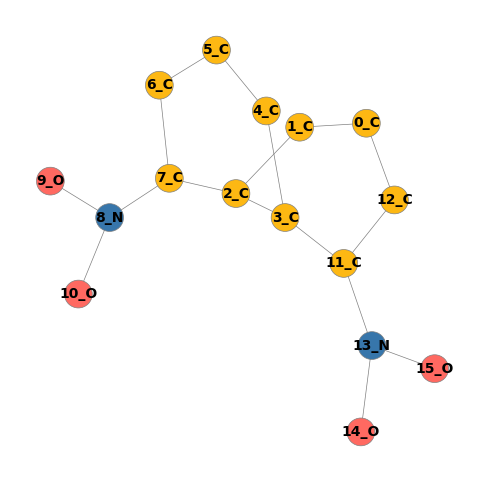

In [8]:
from utils import visualize_mutag_graph
from torch_geometric.utils import to_networkx
import networkx as nx
rule = {'n4_n8': '<=0', 'n4_n13': '<=0', 'n0_n8': '<=0', 'nL_9': 'O', 'n9_n16': '<=0', 'nL_3': 'C', 'nL_14': 'O', 'nL_6': 'C', 'n5_n13': '<=0', 'nL_2': 'C', 'nL_1': 'C', 'n3_n4': '>0', 'n13_n16': '<=0', 'nL_18': 'None', 'nL_5': 'C', 'n6_n12': '<=0', 'n1_n7': '<=0', 'nL_0': 'C', 'n3_n8': '<=0', 'nL_4': 'C', 'nL_16': 'None', 'n8_n15': '<=0', 'n0_n1': '>0', 'nL_15': 'O', 'nL_10': 'O'}
important_nodes = [k for k in rule if k.startswith('nL_')]
important_edges = [k for k in rule if k.startswith('n') and '_n' in k]
G = to_networkx(dataset[49], to_undirected=True, node_attrs="x")
visualize_mutag_graph(G, pos = nx.kamada_kawai_layout(G), node_label=True)


In [7]:
from model.gnnNets import get_gnnNets
model = get_gnnNets(
    input_dim=dataset.num_node_features,
    output_dim=dataset.num_classes,
    model_config=config.models,
)

state_dict = torch.load(
    os.path.join(
        config.models.gnn_saving_path,
        f"{config.datasets.dataset_name}",
        f"{config.models.gnn_name}_"
        f"{len(config.models.param.gnn_latent_dim)}l_latest.pth",
    )
)["net"]

model.load_state_dict(state_dict)

/var/folders/gg/08dxwv590y98p55233w_yc4c0000gn/T/ipykernel_18207/735522710.py:8: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(


<All keys matched successfully>

In [8]:
model.eval()

GCNNet(
  (readout_layer): GNNPool()
  (convs): ModuleList(
    (0): GCNConv(10, 20)
    (1-2): 2 x GCNConv(20, 20)
  )
  (mlps): ModuleList(
    (0): Linear(in_features=20, out_features=2, bias=True)
  )
)

In [ ]:
import random
from torch_geometric.utils.convert import to_networkx
from torch_geometric.utils import from_networkx
import copy
import torch
import networkx as nx
import torch.nn.functional as F
from ged4py import GraphEditDistance
from distance import *
from utils import *

def prepare_networkx_for_pyg(graph_nx):
    for _, data in graph_nx.nodes(data=True):
        for k, v in data.items():
            if isinstance(v, list):
                data[k] = torch.tensor(v, dtype=torch.float)
    for _, _, data in graph_nx.edges(data=True):
        for k, v in data.items():
            if isinstance(v, list):
                data[k] = torch.tensor(v, dtype=torch.float)

def add_bidirectional_edges(edge_index):
    edge_set = set()
    unique_edges = []
    
    for i in range(edge_index.shape[1]):
        u, v = edge_index[:, i].tolist()
        edge = tuple(sorted((u, v)))
        
        if edge not in edge_set:
            edge_set.add(edge)
            unique_edges.append([u, v])

    bidirectional_edges = []
    for u, v in unique_edges:
        bidirectional_edges.append([u, v])
        bidirectional_edges.append([v, u])
    
    return torch.tensor(bidirectional_edges, dtype=torch.long).T

def eval_fitness_so(child_nx, graphX_nx, blackbox):
    child_string = graph_to_string(child_nx.graph)
    graphX_string = graph_to_string(graphX_nx)
    distance = levenshtein_ed(child_string, graphX_string)
    norm_distance = distance / max(len(child_string), len(graphX_string))
    if norm_distance == 0:
        norm_distance = 1
    
    child = from_networkx(child_nx.graph)
    graphX = from_networkx(graphX_nx)
    prob_child, _ = blackbox(child.x, child.edge_index, None)
    prob_G, _ = blackbox(graphX.x, graphX.edge_index, None)
    target_similarity = torch.norm(prob_child - prob_G, p=2).item()

    return 0.5 * norm_distance + 0.5 * target_similarity

def eval_fitness_do(child_nx, blackbox, other_graphs):
    distances = []
    fitness = []
    child = from_networkx(child_nx.graph)
    prob_child, _ = blackbox(child.x, child.edge_index, None)
    child_string = graph_to_string(child_nx.graph)
    for graph, prob in other_graphs:
        graph_string = graph_to_string(graph)
        distance = levenshtein_ed(child_string, graph_string)
        norm_distance = distance / max(len(child_string), len(graph_string))
        if norm_distance == 0:
            norm_distance = 1
            
        target_similarity = torch.norm(prob_child - prob, p=2).item()
        fitness.append(0.5 * norm_distance + 0.5 * target_similarity)
        
            
    if not fitness:
        return 1

    return min(fitness)

class Individual:
    def __init__(self, graph):
        self.graph = graph
        self.fitness = 0

    def clone(self):
        return Individual(copy.deepcopy(self.graph))

    def mutate(self, graphX, blackbox, case_type, DO_graphs):
        mutation_choices = ['add_edge', 'remove_edge', 'change_node', 'add_node', 'remove_node']
        mutation_probs = [0.2, 0.2, 0.2, 0.2, 0.2]
        mutation_type = random.choices(mutation_choices, weights=mutation_probs, k=1)[0]

        mutated_graph = copy.deepcopy(self.graph)
        if mutated_graph.nodes is None or mutated_graph.edges is None:
            return self
        
        any_node = next(iter(mutated_graph.nodes))
        feature_dim = len(mutated_graph.nodes[any_node].get('x'))
        nodes = list(mutated_graph.nodes)
        edges = list(mutated_graph.edges)

        if mutation_type == 'add_edge':
            for _ in range(10):
                u, v = random.sample(nodes, 2)
                if not mutated_graph.has_edge(u, v):
                    mutated_graph.add_edge(u, v)
                    break

        elif mutation_type == 'remove_edge' and edges:
            u, v = random.choice(edges)
            mutated_graph.remove_edge(u, v)

        elif mutation_type == 'add_node':
            new_node_id = max(mutated_graph.nodes) + 1
            new_feature = torch.zeros(feature_dim, dtype=torch.float)
            node_label = random.choice(range(feature_dim))
            new_feature[node_label] = 1
            
            mutated_graph.add_node(new_node_id, x=new_feature)
            
            existing_node = random.choice(nodes)
            if existing_node != new_node_id:
                mutated_graph.add_edge(new_node_id, existing_node)

        elif mutation_type == 'remove_node':
            node = random.choice(nodes)
            mutated_graph.remove_node(node)

        else: #change node label
            node_id = random.choice(nodes)
            old_feature = torch.tensor(mutated_graph.nodes[node_id]['x'], dtype=torch.float)
            current_index = torch.argmax(old_feature).item()
            
            other_indexes = [i for i in range(feature_dim) if i != current_index]
            new_index = random.choice(other_indexes)

            new_feature = torch.zeros(feature_dim, dtype=torch.float)
            new_feature[new_index] = 1.0
            mutated_graph.nodes[node_id]['x'] = new_feature

        if len(mutated_graph.nodes) < 2 or len(mutated_graph.edges) < 1:
            return self
        if not nx.is_connected(mutated_graph):
            return self
        
        prepare_networkx_for_pyg(mutated_graph)
        child = Individual(mutated_graph)
        if case_type == 'sso':
            child.fitness = eval_fitness_so(child, graphX, blackbox)
        else:
            child.fitness = eval_fitness_do(child, blackbox, DO_graphs)
        return child

    def crossover(self, other, graphX, blackbox, case_type, DO_graphs):
        G1 = copy.deepcopy(self.graph)
        G2 = copy.deepcopy(other.graph)

        nodes1 = list(G1.nodes)
        nodes2 = list(G2.nodes)

        cut = random.choice(range(1, len(nodes1)))
        part1 = nodes1[:cut]
        part2 = nodes2[cut:]
        
        child = nx.Graph()

        child.add_nodes_from((n, G1.nodes[n]) for n in part1 if n not in child)
        child.add_nodes_from((n, G2.nodes[n]) for n in part2 if n not in child)

        child.add_edges_from((u, v) for u, v in G1.edges if u in part1 and v in part1)
        child.add_edges_from((u, v) for u, v in G2.edges if u in part2 and v in part2)
        
        child.add_edges_from((u, v) for u, v in G1.edges if (u in part1 and v in part2) or (v in part1 and u in part2))
        child.add_edges_from((u, v) for u, v in G2.edges if (u in part1 and v in part2) or (v in part1 and u in part2))

        if not nx.is_connected(child):
            return self
        
        prepare_networkx_for_pyg(child)
        child = Individual(child)
        if case_type == 'sso':
            child.fitness = eval_fitness_so(child, graphX, blackbox)
        else:
            child.fitness = eval_fitness_do(child, blackbox, DO_graphs)
        return child

def initialize_population(size, graphX, blackbox, case_type, DO_graphs):
    population = []
    for _ in range(size):
        ind_graph = copy.deepcopy(graphX)
        individual = Individual(ind_graph).mutate(graphX, blackbox, case_type, DO_graphs)
        population.append(individual)
    return population

def select_parents(population, ratio):
    unique = {}
    for ind in population:
        if ind.fitness not in unique:
            unique[ind.fitness] = ind
    distinct = list(unique.values())
    distinct.sort(key=lambda x: x.fitness)
    return distinct[:int(ratio * len(distinct))]

def get_graphs_DO_embedding(label, dataset, blackbox):
    DO_graphs_embedding = []
    for i in range(len(dataset)):
        if dataset[i].y.item() != label:
            G = to_networkx(dataset[i], to_undirected=True, node_attrs="x")
            prob, _ = blackbox(dataset[i].x, dataset[i].edge_index, None)
            DO_graphs_embedding.append((G, prob))
    print("Number of graphs with different labels: ", len(DO_graphs_embedding))
    return DO_graphs_embedding

def genetic_algorithm(graphX, population_size, generations, blackbox, test_dataset):
    DO_graphs_embedding = get_graphs_DO_embedding(graphX.graph['y'], test_dataset, blackbox)
    case_types = ['sso','sdo']
    populations = {}

    for case_type in case_types:
        population = initialize_population(population_size // 2, graphX, blackbox, case_type, DO_graphs_embedding)
        
        for gen in range(generations):
            print(f"{case_type} : Generation {gen+1}/{generations}")
            new_population = []
            best = select_parents(population, ratio = 0.1) # xem thang best 
            print(f"Len:{len(best)}")
            new_population.extend(best[:len(best) // 2])
            print(f"Len:{len(new_population)}")
            fitness_set = set(ind.fitness for ind in new_population)

            while len(new_population) < (population_size // 2):
                p1, p2 = random.sample(best, 2)
                
                child = p1.crossover(p2, graphX, blackbox, case_type, DO_graphs_embedding)
                child = child.mutate(graphX, blackbox, case_type, DO_graphs_embedding)
                
                if all(abs(child.fitness - f) > 1e-8 for f in fitness_set):
                    fitness_set.add(child.fitness)
                    new_population.append(child)
                
                    
            population = new_population
            
        populations[case_type] = population
    return populations


In [857]:
G1 = to_networkx(dataset[33], to_undirected=True, node_attrs="x")
G2 = to_networkx(dataset[25], to_undirected=True, node_attrs="x")

In [845]:
G1 = Individual(G1)
G2 = Individual(G2)

In [855]:
while True:
    child = G1.crossover(G2, G1.graph, model, 'sso', [])
    if child != G1:
        break

Cut point: 12


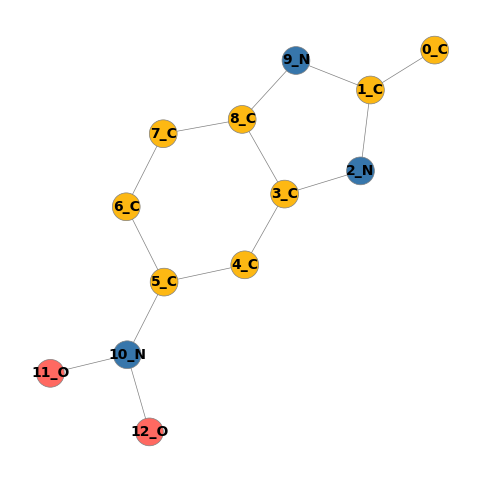

In [843]:
data = to_networkx(dataset[146]
                   , to_undirected=True, node_attrs="x")
pos = nx.kamada_kawai_layout(data)
visualize_mutag_graph(data, pos=nx.kamada_kawai_layout(data), node_label=True)

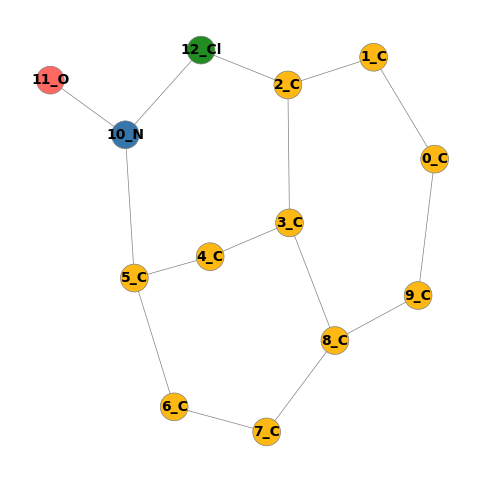

In [856]:

visualize_mutag_graph(child.graph, pos=nx.kamada_kawai_layout(child.graph),node_label=True)

In [13]:
test_dataset = [dataset[i] for i in test_indices]
graphX = copy.deepcopy(dataset[49])
graphX = to_networkx(graphX, to_undirected=True, node_attrs="x")
graphX.graph['y'] = dataset[49].y.item()
final_populations = genetic_algorithm(graphX=graphX, population_size=100, generations=2, 
                                blackbox= model, test_dataset=test_dataset)

Number of graphs with different labels:  3


/Users/admin/Documents/Screenshots/LORE/utils.py:30: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x_tensor = torch.tensor(x)


sso : Generation 1/2
Len:3
Len:1


/var/folders/gg/08dxwv590y98p55233w_yc4c0000gn/T/ipykernel_50223/296371828.py:130: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  old_feature = torch.tensor(mutated_graph.nodes[node_id]['x'], dtype=torch.float)


sso : Generation 2/2
Len:5
Len:2
sdo : Generation 1/2
Len:3
Len:1
sdo : Generation 2/2
Len:5
Len:2


In [78]:
import random
from torch_geometric.utils import from_networkx
def mask(G, rule):
    feature_dim = len(G.nodes[0].get('x')) if G.nodes else 0
    G_maskout = G.copy()
    G_mask = nx.Graph()
    
    for key, cond in rule.items():
        if '_' in key and not key.startswith('nL_'): # edge
            u, v = key.split('_')
            u, v = int(u[1:]), int(v[1:])
            if cond == '>0':
                if not G_mask.has_edge(u, v):
                    if not G_mask.has_node(u) and G.has_node(u):
                        attrs = G.nodes[u]
                        G_mask.add_node(u, **attrs)
                    if not G_mask.has_node(v) and G.has_node(v):
                        attrs = G.nodes[v]
                        G_mask.add_node(v, **attrs)
                    G_mask.add_edge(u, v)
                
                if G_maskout.has_edge(u, v):
                    G_maskout.remove_edge(u, v)
                    
            # elif cond == '<=0':
            #     if not G_maskout.has_edge(u, v):
            #         if not G_maskout.has_node(u):
            #             new_feature = torch.zeros(feature_dim, dtype=torch.float)
            #             new_feature[0] = 1
            #             G_maskout.add_node(u, x=new_feature)
            #         if not G_maskout.has_node(v):
            #             new_feature = torch.zeros(feature_dim, dtype=torch.float)
            #             new_feature[0] = 1
            #             G_maskout.add_node(v, x=new_feature)
            #         G_maskout.add_edge(u, v)
                    

        elif key.startswith('nL_'): # node label
            node_id = int(key.split('_')[1])
            if cond != 'None':
                if G_maskout.has_node(node_id):
                    G_maskout.remove_node(node_id)
                    
                if not G_mask.has_node(node_id) and G.has_node(node_id):
                    attrs = G.nodes[node_id]
                    G_mask.add_node(node_id, **attrs)
                    
            # else:
            #     if not G_maskout.has_node(node_id):
            #         new_feature = torch.zeros(feature_dim, dtype=torch.float)
            #         new_feature[0] = 1
            #         G_maskout.add_node(node_id, x=new_feature)
                    
    return G_maskout, G_mask

def evaluate(model, graph, rule, device='cpu'):
    G = to_networkx(graph, to_undirected=True, node_attrs="x")
    l, _ = model(graph.x, graph.edge_index, None)
    p = l.squeeze(0).softmax(dim=-1)
    print(f"Prediction: {p}")
    target_class = torch.argmax(p).item()  
    conf_target = p[target_class].item()
    
    G_maskout, G_mask = mask(G, rule)
    
    if G_maskout.number_of_nodes() < 1:
        fidelity = 0
    else:
        g_maskout = from_networkx(G_maskout)
        l_mo, _ = model(g_maskout.x, g_maskout.edge_index, None)
        p_mo = l_mo.squeeze(0).softmax(dim=-1)
        print(f"Maskout Prediction: {p_mo}")
        conf_maskout = p_mo[target_class].item()
        
        fidelity = conf_target - conf_maskout
    
    if G_mask.number_of_nodes() < 1:
        inv_fidelity = 0
    else:
        g_mask = from_networkx(G_mask)
        l_m, _ = model(g_mask.x, g_mask.edge_index, None)
        p_m = l_m.squeeze(0).softmax(dim=-1)
        print(f"Mask Prediction: {p_m}")
        conf_mask = p_m[target_class].item()
        
        inv_fidelity = conf_target - conf_mask

    total_nodes = G.number_of_nodes()
    explained_nodes = G_mask.number_of_nodes()
    sparsity = 1 - (explained_nodes / total_nodes)

    return fidelity, inv_fidelity, sparsity

In [81]:
rule = {'nL_1': 'C', 'nL_19': 'None', 'nL_0': 'C', 'nL_8': 'C', 'nL_15': 'O', 'nL_10': 'C'}

important_nodes = [k for k in rule if k.startswith('nL_')]
important_edges = [k for k in rule if k.startswith('n') and '_n' in k]

G_maskout, G_mask = mask(G, rule)
data = from_networkx(G_mask)
l, _ = model(data.x, data.edge_index, None)
p = l.squeeze(0).softmax(dim=-1)
p

tensor([0.0107, 0.9893], grad_fn=<SoftmaxBackward0>)

In [13]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

tensor = torch.load("./example_60.pt")

print(type(tensor))

<class 'numpy.ndarray'>


/var/folders/gg/08dxwv590y98p55233w_yc4c0000gn/T/ipykernel_45189/3551466784.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  tensor = torch.load("./example_60.pt")


Top indices: [0, 3, 2, 5, 13, 4, 9, 21, 24, 20]
[ 0.87740707 -0.44404507  0.6147415   0.66646725  0.08548026  0.59450341
 -0.33126259 -0.53606689 -0.28010441 -0.00396085 -0.37002945 -0.10585479
 -0.26611567  0.31477165 -0.32461261 -0.11089611 -0.38075233 -0.18698998
 -0.14948654 -0.24209213 -0.10492611 -0.00822067 -0.51772529 -0.54952526
 -0.06163915]


/var/folders/gg/08dxwv590y98p55233w_yc4c0000gn/T/ipykernel_47362/890926461.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  node_scores = torch.load(f"./node_scores/examp

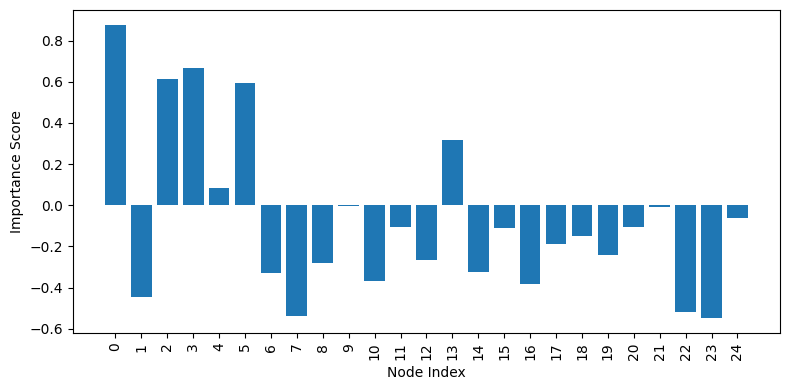

In [23]:
import matplotlib.pyplot as plt

node_scores = torch.load(f"./node_scores/example_60.pt")
scores_tensor = torch.tensor(node_scores, dtype=torch.float32)
top_idx = scores_tensor.argsort(descending=True).tolist()
print(f"Top indices: {top_idx[:10]}")
node_ids = [i for i in range(len(node_scores))]
print(node_scores   )
# Vẽ biểu đồ với node index dưới từng cột
plt.figure(figsize=(8, 4))
plt.bar(node_ids, node_scores)

# Hiển thị toàn bộ node index dưới mỗi cột
plt.xticks(ticks=node_ids, labels=node_ids, rotation=90)

plt.xlabel("Node Index")
plt.ylabel("Importance Score")
plt.tight_layout()
plt.show()